# 沪深300多因子选股策略研究报告

**作者**: [彭海迪]
**数据源**: AkShare (沪深300成分股)
**回测区间**: 月频 (每月末调仓)
**交易成本**: 双边千分之三 (包括手续费和滑点估算)

## 1.研究目标
本项目基于沪深300大盘蓝筹股数据，构建技术面因子(动量、反转、波动率)。旨在验证其在A股沪深300股票池中的有效性，并在剥离交易成本后，挖掘非线性特征(两端效应)带来的超额收益。

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
from IPython.display import Image,display

plt.rcParams['font.sans-serif']=['SimHei','Microsoft YaHei']
plt.rcParams['axes.unicode_minus']=False

BASE_DIR=os.path.dirname(os.getcwd())
print(f"当前项目根目录:{BASE_DIR}")


当前项目根目录:c:\Users\lenovo\Desktop\Quant_project


## 2.因子有效性实证分析

在构建组合前，需要检验因子对未来收益的预测能力。本节展示因子评价脚本生成的IC序列与分层回测图。

===因子IC序列图===


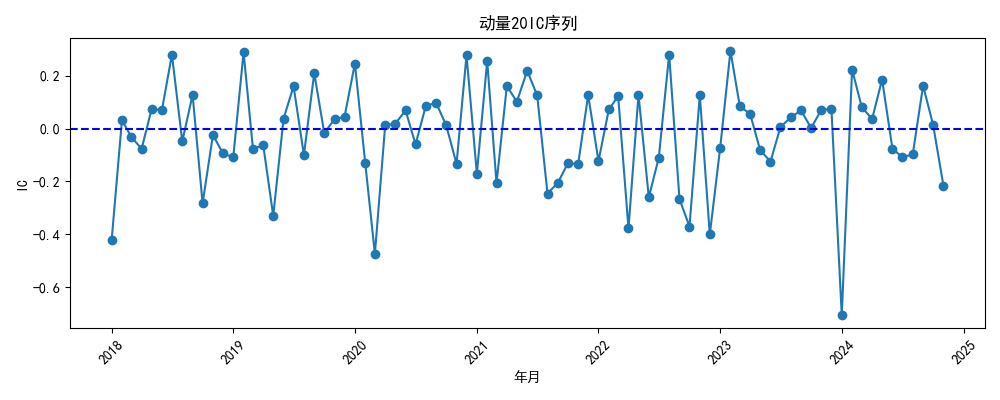

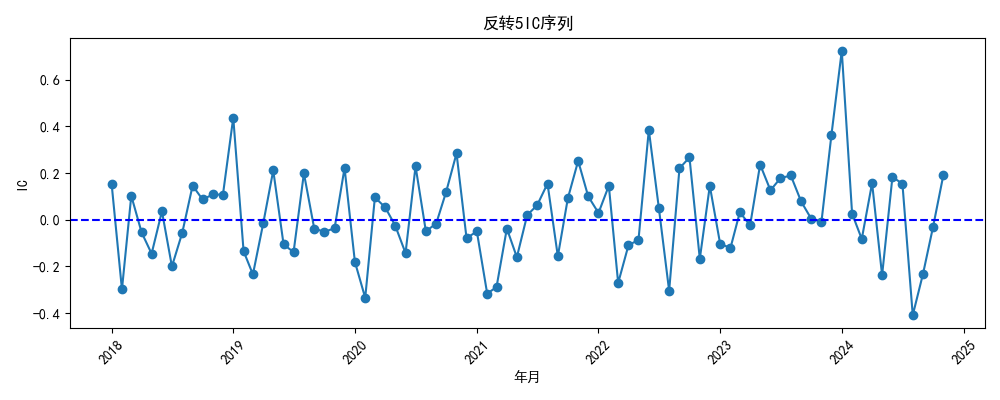

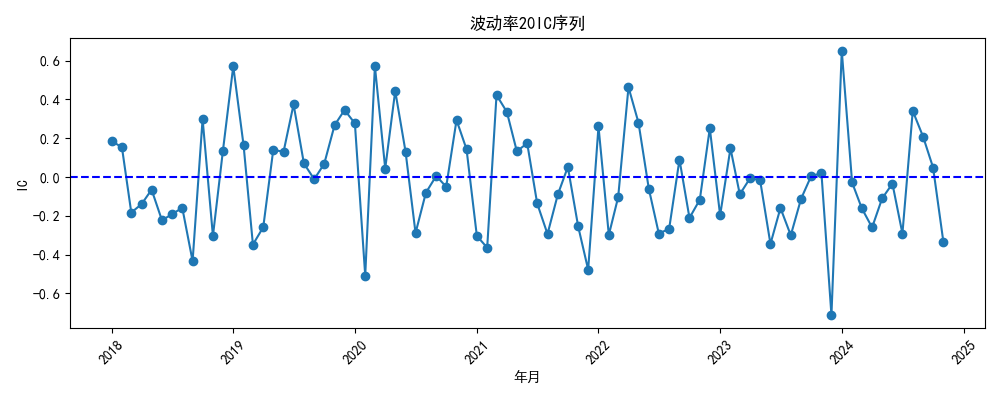

In [2]:
print("===因子IC序列图===")
display(Image(filename=os.path.join(BASE_DIR,"results","动量20_IC.png")))
display(Image(filename=os.path.join(BASE_DIR,"results","反转5_IC.png")))
display(Image(filename=os.path.join(BASE_DIR,"results","波动率20_IC.png")))

===因子分层累计收益图===


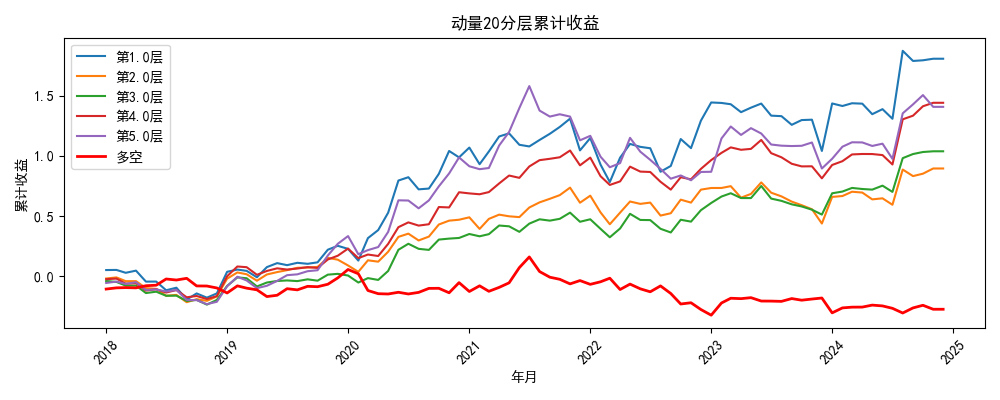

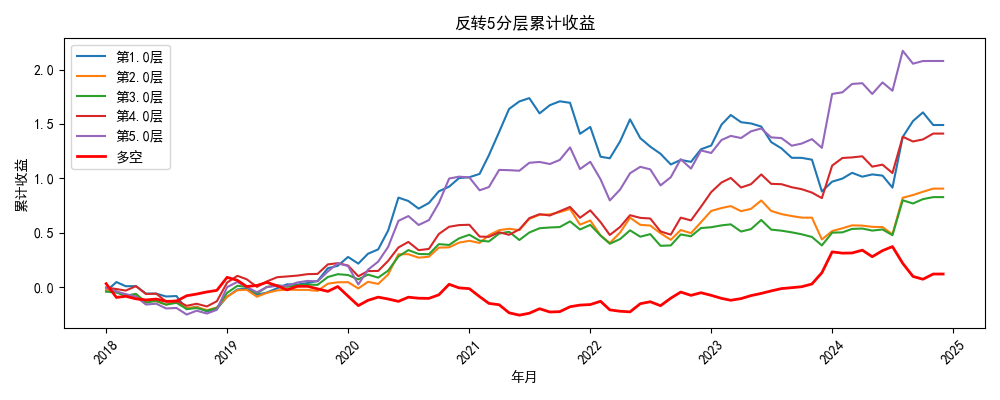

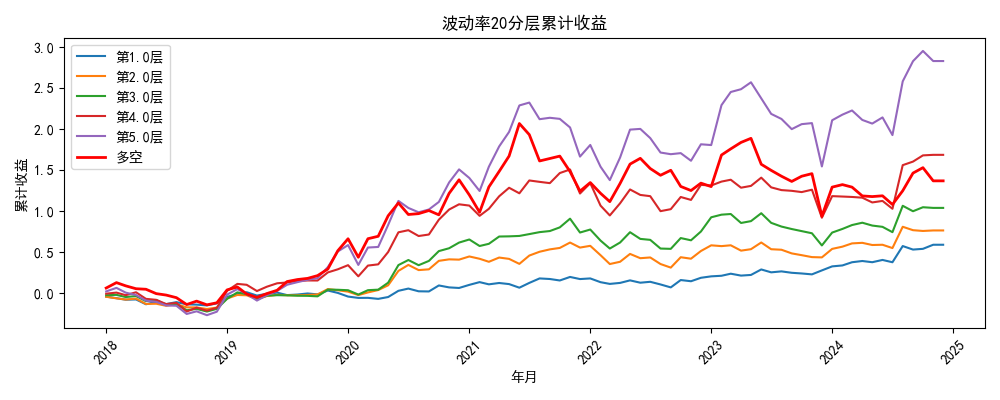

In [3]:
print("===因子分层累计收益图===")
display(Image(filename=os.path.join(BASE_DIR,"results","动量20_layered.png")))
display(Image(filename=os.path.join(BASE_DIR,"results","反转5_layered.png")))
display(Image(filename=os.path.join(BASE_DIR,"results","波动率20_layered.png")))

### 2.1实证结论
- **动量与反转因子(非线性特征)**: 分层图呈现明显的“V型”。极端超跌股(有反弹动能)和极端强势股(有惯性动能)表现均优于中间层。
- **波动率因子(溢价特征)**: 高波动组合(第5层)的长期复利收益远超低波动组合。这说明在沪深300池中，高弹性、高波动资产具备极强的爆发力(虽伴随高回撤)。

In [4]:
compare_data={
    "策略版本":["V1(线性版)","V2(非线性版)"],
    "累计收益":["244.79%","318.58%"],
    "年化收益":["19.59%","23.00%"],
    "年化波动":["26.36%","28.70%"],
    "夏普比率":[0.66,0.73],
    "卡玛比率":[0.65,0.81],
    "月胜率":["55.42%","60.24%"]
}
compare_df=pd.DataFrame(compare_data)
print("===策略全指标迭代对比表===")
display(compare_df.set_index("策略版本").T)

===策略全指标迭代对比表===


策略版本,V1(线性版),V2(非线性版)
累计收益,244.79%,318.58%
年化收益,19.59%,23.00%
年化波动,26.36%,28.70%
夏普比率,0.66,0.73
卡玛比率,0.65,0.81
月胜率,55.42%,60.24%


=== V1(线性版) 累计净值曲线 ===


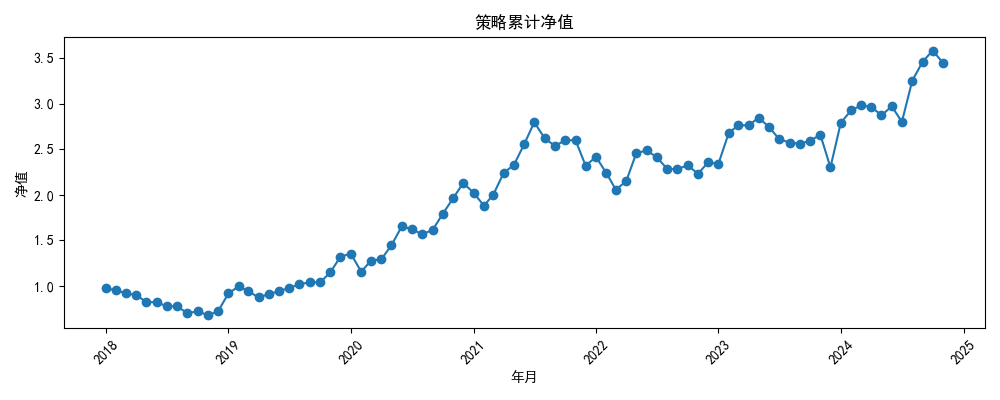


=== V2(非线性版) 累计净值曲线 ===


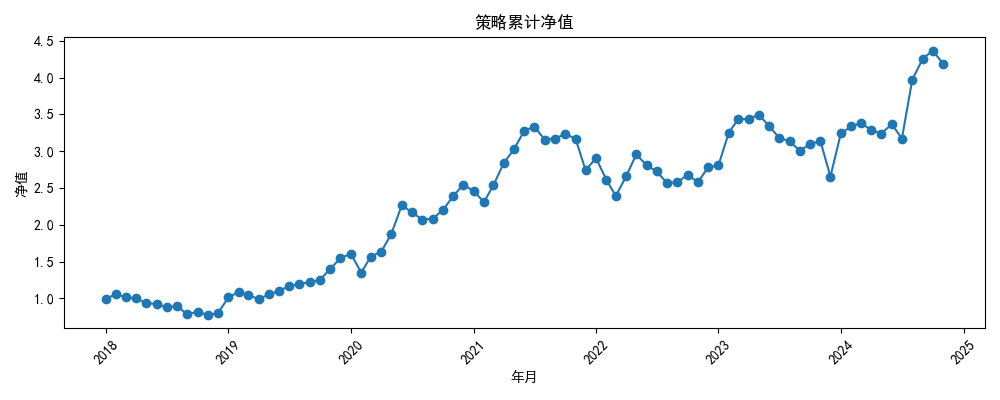

In [5]:
print("=== V1(线性版) 累计净值曲线 ===")
display(Image(filename=os.path.join(BASE_DIR,"results","strategy_V1_raw_nav.png")))
print("\n=== V2(非线性版) 累计净值曲线 ===")
display(Image(filename=os.path.join(BASE_DIR,"results","strategy_V2_nonlinear_nav.png")))

## 3. 核心突破：从线性到非线性的进化
传统的多因子模型往往假设因子与收益呈线性关系（即得分越高收益越高）。但在项目初期（V1线性版）中，我们发现直接买入因子值最大的股票，虽然获得了 19.59% 的年化收益，但面临着胜率偏低（55%）和回撤过大（-30%）的困境。

**V2进化**：
通过对分层图的敏锐观察，我们放弃了对单一方向的押注，利用**绝对偏离度**直接捕捉动量和反转因子的“两端极端值”，同时保留高波动因子的暴露。

**结果**：这一逻辑重构，使得累计收益突破 **318%**，年化收益达到 **23.00%**。同时，最大回撤略微收敛，而最令人惊艳的是**月胜率突破了 60%**，卡玛比率提升至 0.81。这意味着策略在保证高爆发力的同时，盈亏比和持有体验得到了实质性的优化。